<a href="https://colab.research.google.com/github/raghavgate/Machine-Learning-and-Artificial-Intelligence-Projects/blob/main/GraphRAG_EECS295.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🔗 GraphRAG — EECS 295 Project
**Graph Retrieval-Augmented Generation for Structured Question Answering**

This notebook implements the full GraphRAG pipeline
- 🤗 `transformers` + `FLAN-T5` or `Mistral-7B` for generation
- `spaCy` for entity extraction
- `NetworkX` for knowledge graph
- `FAISS` + `sentence-transformers` for vector retrieval

**Runtime:** Set to `T4 GPU` (Runtime → Change runtime type → T4)

## 📦 Cell 1 — Install Dependencies

In [ ]:
!pip install -q transformers accelerate bitsandbytes
!pip install -q sentence-transformers faiss-cpu networkx spacy
!pip install -q datasets huggingface_hub
!python -m spacy download en_core_web_sm
print('✅ All dependencies installed')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 30.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 127.6 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
✅ All dependencies installed


## 🔧 Cell 2 — Imports & Config

In [ ]:
import os, re, json
import numpy as np
import networkx as nx
import spacy
import faiss
import torch
from collections import defaultdict
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, pipeline

# ── Config ──────────────────────────────────────────────────────────
# Two model options — start with FLAN-T5 (fast, no GPU needed).
# Switch to Mistral for better quality if you have T4 GPU.
MODEL_CHOICE = "flan-t5"  # options: "flan-t5" | "mistral"

EMBED_MODEL  = "all-MiniLM-L6-v2"   # fast & free sentence embeddings
K_HOP        = 1                     # graph traversal depth
TOP_K        = 3                     # chunks/subgraphs to retrieve
CHUNK_SIZE   = 200                   # words per text chunk
DEVICE       = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")

Device: cuda


## 🤖 Cell 3 — Load LLM (FLAN-T5 or Mistral)
> **FLAN-T5-large** (~800MB) runs on CPU/GPU, great for testing.  
> **Mistral-7B-Instruct** (4-bit quantized, ~5GB) needs T4 GPU for good speed.

In [ ]:
if MODEL_CHOICE == "flan-t5":
    MODEL_ID = "google/flan-t5-xl"   # swap to flan-t5-xl for more power
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
    model     = AutoModelForSeq2SeqLM.from_pretrained(MODEL_ID, torch_dtype=torch.float16 if DEVICE=="cuda" else torch.float32)
    model.to(DEVICE)

    def generate_answer(prompt: str, max_new_tokens: int = 256) -> str:
        inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=1024).to(DEVICE)
        with torch.no_grad():
            out = model.generate(**inputs, max_new_tokens=max_new_tokens, num_beams=4)
        return tokenizer.decode(out[0], skip_special_tokens=True)

else:  # mistral — requires T4 GPU
    from transformers import BitsAndBytesConfig
    MODEL_ID = "mistralai/Mistral-7B-Instruct-v0.2"
    bnb_cfg  = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16)
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
    # NOTE: First time downloads ~5 GB — be patient!
    model = pipeline("text-generation", model=MODEL_ID,
                     model_kwargs={"quantization_config": bnb_cfg},
                     device_map="auto")

    def generate_answer(prompt: str, max_new_tokens: int = 256) -> str:
        out = model(prompt, max_new_tokens=max_new_tokens, do_sample=False)
        return out[0]["generated_text"].split("Answer:")[-1].strip()

print(f"✅ LLM loaded: {MODEL_ID}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/558 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

✅ LLM loaded: google/flan-t5-xl


## 📚 Cell 4 — Sample Documents
> Replace `DOCUMENTS` with your own corpus (Wikipedia dumps, academic papers, etc.)  
> Each entry is a dict: `{"id": str, "text": str}`

In [ ]:
# DOCUMENTS = [
#     {"id": "doc1", "text": "Alan Turing was a British mathematician who worked at Bletchley Park during World War II. He developed the Turing machine, a theoretical model of computation."},
#     {"id": "doc2", "text": "Bletchley Park was a codebreaking centre in England. Mathematicians including Alan Turing helped crack the Enigma cipher there."},
#     {"id": "doc3", "text": "The Enigma machine was an encryption device used by Nazi Germany. Breaking the Enigma cipher shortened World War II by several years."},
#     {"id": "doc4", "text": "The Turing Award is given annually by the ACM. It is considered the Nobel Prize of computing. Recipients include Yoshua Bengio, Geoffrey Hinton, and Yann LeCun."},
#     {"id": "doc5", "text": "Deep learning was popularized by Geoffrey Hinton, Yoshua Bengio, and Yann LeCun, who shared the 2018 Turing Award for their contributions to neural networks."},
#     {"id": "doc6", "text": "Neural networks are computational models inspired by the human brain. They are the backbone of modern deep learning systems."},
#     {"id": "doc7", "text": "Yoshua Bengio leads the Mila institute in Montreal, Canada. His research focuses on deep generative models and AI safety."},
#     {"id": "doc8", "text": "Geoffrey Hinton worked at Google Brain before leaving in 2023 to speak freely about AI risks. He pioneered backpropagation and deep belief networks."},
# ]

from datasets import load_dataset

ds = load_dataset("hotpot_qa", "distractor", split="train[:200]")

DOCUMENTS = []
for i, row in enumerate(ds):
    for title, sentences in zip(row["context"]["title"], row["context"]["sentences"]):
        full_text = " ".join(sentences)
        DOCUMENTS.append({"id": f"{i}_{title}", "text": full_text})

print(f"✅ {len(DOCUMENTS)} documents loaded")

README.md: 0.00B [00:00, ?B/s]

distractor/train-00000-of-00002.parquet:   0%|          | 0.00/166M [00:00<?, ?B/s]

distractor/train-00001-of-00002.parquet:   0%|          | 0.00/166M [00:00<?, ?B/s]

distractor/validation-00000-of-00001.par(…):   0%|          | 0.00/27.5M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/90447 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/7405 [00:00<?, ? examples/s]

✅ 2000 documents loaded


## ✂️ Cell 5 — Text Chunking (for Baseline RAG)

In [ ]:
def chunk_text(doc: dict, chunk_size: int = CHUNK_SIZE) -> list[dict]:
    """Split doc text into word-level chunks."""
    words  = doc["text"].split()
    chunks = []
    for i in range(0, len(words), chunk_size):
        chunk_text = " ".join(words[i:i + chunk_size])
        chunks.append({"doc_id": doc["id"], "chunk_id": f"{doc['id']}_c{i}", "text": chunk_text})
    return chunks

all_chunks = [c for doc in DOCUMENTS for c in chunk_text(doc)]
print(f"✅ {len(all_chunks)} chunks created")

✅ 2098 chunks created


## 🧲 Cell 6 — Embeddings + FAISS Index (Baseline RAG)

In [ ]:
print("Loading sentence-transformer...")
embedder = SentenceTransformer(EMBED_MODEL)

chunk_texts  = [c["text"] for c in all_chunks]
chunk_embeds = embedder.encode(chunk_texts, show_progress_bar=True, convert_to_numpy=True)
chunk_embeds = chunk_embeds / np.linalg.norm(chunk_embeds, axis=1, keepdims=True)  # L2-normalize

dim        = chunk_embeds.shape[1]
faiss_index = faiss.IndexFlatIP(dim)   # Inner Product = cosine after normalization
faiss_index.add(chunk_embeds)
print(f"✅ FAISS index built: {faiss_index.ntotal} vectors, dim={dim}")

Loading sentence-transformer...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (6 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/66 [00:00<?, ?it/s]

✅ FAISS index built: 2098 vectors, dim=384


## 🕸️ Cell 7 — Entity Extraction + Knowledge Graph Construction

In [ ]:
nlp = spacy.load("en_core_web_sm")
G   = nx.Graph()

# ── Entity extraction ─────────────────────────────────────────────────
doc_entities: dict[str, list[str]] = {}   # doc_id → [entity, ...]
entity_to_docs: dict[str, list[str]] = defaultdict(list)  # entity → [doc_id, ...]

ALLOWED_LABELS = {"PERSON", "ORG", "GPE", "PRODUCT", "WORK_OF_ART", "EVENT", "FAC", "LOC"}

for doc in DOCUMENTS:
    spacy_doc = nlp(doc["text"])
    ents = list({ent.text.strip() for ent in spacy_doc.ents
                 if ent.label_ in ALLOWED_LABELS and len(ent.text.strip()) > 1})
    doc_entities[doc["id"]] = ents

    # Add node for each entity
    for e in ents:
        G.add_node(e, docs=[doc["id"]])
        entity_to_docs[e].append(doc["id"])

    # Add edges between entities that co-occur in the same document
    for i in range(len(ents)):
        for j in range(i + 1, len(ents)):
            if G.has_edge(ents[i], ents[j]):
                G[ents[i]][ents[j]]["weight"] += 1
            else:
                G.add_edge(ents[i], ents[j], weight=1, source_doc=doc["id"])

print(f"✅ Knowledge Graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")
print(f"   Sample entities: {list(G.nodes)[:10]}")

✅ Knowledge Graph: 12215 nodes, 92207 edges
   Sample entities: ['Hyderabad', 'New Media', 'Mumbai', 'Lucknow', 'Hindi', 'Bengaluru', 'India', 'New Delhi', 'Chennai', 'Visakhapatnam']


## 🔍 Cell 8 — GraphRAG Retrieval (k-hop subgraph)

In [ ]:
def extract_query_entities(query: str) -> list[str]:
    """Extract named entities from the query using spaCy."""
    doc = nlp(query)
    ents = [ent.text.strip() for ent in doc.ents if ent.label_ in ALLOWED_LABELS]
    # Fallback: fuzzy match tokens against graph nodes if spaCy misses something
    if not ents:
        tokens = query.split()
        ents = [n for n in G.nodes for tok in tokens if tok.lower() in n.lower()]
    return list(set(ents))


def get_khop_subgraph(seed_entities: list[str], k: int = K_HOP) -> nx.Graph:
    """Return the k-hop ego subgraph around all seed entities."""
    nodes = set()
    for ent in seed_entities:
        # Find best matching node (case-insensitive)
        matched = [n for n in G.nodes if n.lower() == ent.lower()]
        if not matched:
            matched = [n for n in G.nodes if ent.lower() in n.lower()]
        for m in matched:
            ego = nx.ego_graph(G, m, radius=k)
            nodes.update(ego.nodes)
    return G.subgraph(nodes)


def subgraph_to_text(subgraph: nx.Graph) -> str:
    # Don't return raw triplets — just return which docs are relevant
    relevant_docs = set()
    for u, v, data in subgraph.edges(data=True):
        relevant_docs.add(data.get("source_doc", ""))
    return ""  # let the document context do the work instead


def graphrag_retrieve(query: str, top_k: int = TOP_K) -> str:
    """Full GraphRAG retrieval: entities → subgraph → text context."""
    q_entities = extract_query_entities(query)
    print(f"  [GraphRAG] Entities found: {q_entities}")

    subgraph  = get_khop_subgraph(q_entities, k=K_HOP)
    graph_ctx = subgraph_to_text(subgraph)

    # Also pull full doc text for nodes in the subgraph
    relevant_doc_ids = set()
    for node in subgraph.nodes:
        relevant_doc_ids.update(entity_to_docs.get(node, []))

    # Rank those docs by semantic similarity to query
    if relevant_doc_ids:
        cand_texts  = [next(d["text"] for d in DOCUMENTS if d["id"] == did) for did in relevant_doc_ids]
        q_emb       = embedder.encode([query], convert_to_numpy=True)
        q_emb       = q_emb / np.linalg.norm(q_emb, axis=1, keepdims=True)
        cand_embs   = embedder.encode(cand_texts, convert_to_numpy=True)
        cand_embs   = cand_embs / np.linalg.norm(cand_embs, axis=1, keepdims=True)
        scores      = (q_emb @ cand_embs.T).flatten()
        top_indices = scores.argsort()[::-1][:top_k]
        doc_ctx     = "\n\n".join(cand_texts[i] for i in top_indices)
    else:
        doc_ctx = ""

    context = ""
    if graph_ctx:
        context += "=== Graph Relationships ===\n" + graph_ctx + "\n\n"
    if doc_ctx:
        context += "=== Relevant Documents ===\n" + doc_ctx
    return context

print("✅ GraphRAG retrieval functions ready")

✅ GraphRAG retrieval functions ready


## 📖 Cell 9 — Baseline RAG Retrieval

In [ ]:
def vanilla_rag_retrieve(query: str, top_k: int = TOP_K) -> str:
    """Standard RAG: embed query → FAISS nearest neighbors."""
    q_emb = embedder.encode([query], convert_to_numpy=True)
    q_emb = q_emb / np.linalg.norm(q_emb, axis=1, keepdims=True)
    scores, indices = faiss_index.search(q_emb, top_k)
    retrieved = [all_chunks[i]["text"] for i in indices[0]]
    return "\n\n".join(retrieved)

print("✅ Baseline RAG ready")

✅ Baseline RAG ready


## 💬 Cell 10 — Prompt Templates + Answer Generation

In [ ]:
def build_prompt(context: str, question: str, mode: str = "graphrag") -> str:
    clean_context = re.sub(r'=== .+ ===\n', '', context).strip()
    return (
        f"Context: {clean_context}\n\n"
        f"Question: {question}\n"
        f"Answer:"
    )


def ask(question: str, verbose: bool = True) -> dict:
    """Run both Vanilla RAG and GraphRAG, return answers for comparison."""
    print(f"\n{'='*65}")
    print(f"❓ Question: {question}")
    print(f"{'='*65}")

    # ── Vanilla RAG ──────────────────────────────────────────────────
    rag_ctx    = vanilla_rag_retrieve(question)
    rag_prompt = build_prompt(rag_ctx, question, mode="rag")
    rag_answer = generate_answer(rag_prompt)

    # ── GraphRAG ─────────────────────────────────────────────────────
    graph_ctx    = graphrag_retrieve(question)
    graph_prompt = build_prompt(graph_ctx, question, mode="graphrag")
    graph_answer = generate_answer(graph_prompt)

    if verbose:
        print(f"\n📄 Vanilla RAG Context:\n{rag_ctx[:400]}...")
        print(f"\n🔵 Vanilla RAG Answer:\n  {rag_answer}")
        print(f"\n🕸️  GraphRAG Context:\n{graph_ctx[:400]}...")
        print(f"\n🟢 GraphRAG Answer:\n  {graph_answer}")

    return {"question": question, "rag_answer": rag_answer, "graph_answer": graph_answer}

print("✅ QA pipeline ready")

✅ QA pipeline ready


## 🚀 Cell 11 — Run QA Examples
Multi-hop questions that require connecting entities across documents.

In [ ]:
# # Single-hop question
# r1 = ask("Where did Alan Turing work during World War II?")

# Replace your hardcoded questions in Cell 11 with:
from datasets import load_dataset
hotpot = load_dataset("hotpot_qa", "distractor", split="train[:200]")

# Ask the first 3 questions from the actual dataset
for row in list(hotpot)[:3]:
    r = ask(row["question"])
    print(f"Gold answer: {row['answer']}\n")


❓ Question: Which magazine was started first Arthur's Magazine or First for Women?
  [GraphRAG] Entities found: ["Arthur's Magazine"]

📄 Vanilla RAG Context:
Arthur's Magazine (1844–1846) was an American literary periodical published in Philadelphia in the 19th century. Edited by T.S. Arthur, it featured work by Edgar A. Poe, J.H. Ingraham, Sarah Josepha Hale, Thomas G. Spear, and others. In May 1846 it was merged into "Godey's Lady's Book".

First for Women is a woman's magazine published by Bauer Media Group in the USA. The magazine was started in 19...

🔵 Vanilla RAG Answer:
  Arthur's Magazine (1844–1846) was an American literary periodical published in Philadelphia in the 19th

🕸️  GraphRAG Context:
=== Relevant Documents ===
Arthur's Magazine (1844–1846) was an American literary periodical published in Philadelphia in the 19th century.  Edited by T.S. Arthur, it featured work by Edgar A. Poe, J.H. Ingraham, Sarah Josepha Hale, Thomas G. Spear, and others.  In May 1846 it was mer

In [ ]:
# # Multi-hop question: requires connecting Turing → Bletchley → Enigma
# r2 = ask("What cipher did Alan Turing help crack, and what device used that cipher?")

# In Cell 11, filter for hard multi-hop questions only
hard_questions = [row for row in hotpot if row["type"] == "comparison"][:3]
for row in hard_questions:
    r = ask(row["question"])
    print(f"Gold answer: {row['answer']}\n")


❓ Question: Which magazine was started first Arthur's Magazine or First for Women?
  [GraphRAG] Entities found: ["Arthur's Magazine"]

📄 Vanilla RAG Context:
Arthur's Magazine (1844–1846) was an American literary periodical published in Philadelphia in the 19th century. Edited by T.S. Arthur, it featured work by Edgar A. Poe, J.H. Ingraham, Sarah Josepha Hale, Thomas G. Spear, and others. In May 1846 it was merged into "Godey's Lady's Book".

First for Women is a woman's magazine published by Bauer Media Group in the USA. The magazine was started in 19...

🔵 Vanilla RAG Answer:
  Arthur's Magazine (1844–1846) was an American literary periodical published in Philadelphia in the 19th

🕸️  GraphRAG Context:
=== Relevant Documents ===
Arthur's Magazine (1844–1846) was an American literary periodical published in Philadelphia in the 19th century.  Edited by T.S. Arthur, it featured work by Edgar A. Poe, J.H. Ingraham, Sarah Josepha Hale, Thomas G. Spear, and others.  In May 1846 it was mer

In [ ]:
# Multi-hop: Turing Award → 2018 winners → their institution
r3 = ask("Which institute does the 2018 Turing Award winner who works on AI safety lead?")


❓ Question: Which institute does the 2018 Turing Award winner who works on AI safety lead?
  [GraphRAG] Entities found: ['AI']

📄 Vanilla RAG Context:
The Academy Award for Best Director (officially known as the Academy Award for Best Directing) is an award presented annually by the Academy of Motion Picture Arts and Sciences (AMPAS). It is given in honor of a film director who has exhibited outstanding directing while working in the film industry.

The Andre Norton Award for Young Adult Science Fiction and Fantasy is an annual award presented b...

🔵 Vanilla RAG Answer:
  unanswerable

🕸️  GraphRAG Context:
=== Relevant Documents ===
The Andre Norton Award for Young Adult Science Fiction and Fantasy is an annual award presented by the Science Fiction and Fantasy Writers of America (SFWA) to the author of the best young adult or middle grade science fiction or fantasy book published in the United States in the preceding year.  It is named to honor prolific science fiction and fantasy 

## 📊 Cell 12 — Evaluation (Exact Match + F1)
Add gold answers to compute automatic metrics.

In [ ]:
from collections import Counter

def normalize(text: str) -> str:
    return re.sub(r'[^a-z0-9 ]', '', text.lower()).strip()

def exact_match(pred: str, gold: str) -> int:
    return int(normalize(pred) == normalize(gold))

def token_f1(pred: str, gold: str) -> float:
    pred_toks = normalize(pred).split()
    gold_toks = normalize(gold).split()
    common    = Counter(pred_toks) & Counter(gold_toks)
    if not common:
        return 0.0
    prec = sum(common.values()) / len(pred_toks)
    rec  = sum(common.values()) / len(gold_toks)
    return 2 * prec * rec / (prec + rec)


# ── Evaluation set ────────────────────────────────────────────────────
# Format: {"question": ..., "gold": ...}
# Replace gold answers with your dataset's ground truth.
# eval_set = [
#     {"question": "Where did Alan Turing work during World War II?",
#      "gold": "Bletchley Park"},
#     {"question": "What cipher did Alan Turing help crack, and what device used that cipher?",
#      "gold": "Enigma cipher, Enigma machine"},
#     {"question": "Which institute does the 2018 Turing Award winner who works on AI safety lead?",
#      "gold": "Mila institute"},
#     {"question": "Why did Geoffrey Hinton leave Google?",
#      "gold": "to speak freely about AI risks"},
# ]
from datasets import load_dataset
hotpot = load_dataset("hotpot_qa", "distractor", split="train[:200]")

# Use the same comparison questions you just ran in Cell 11
hard_questions = [row for row in hotpot if row["type"] == "comparison"][:20]

eval_set = [{"question": row["question"], "gold": row["answer"]}
            for row in hard_questions]
results = []

for item in eval_set:
    r = ask(item["question"], verbose=False)
    r["gold"] = item["gold"]
    r["rag_em"]    = exact_match(r["rag_answer"],   item["gold"])
    r["graph_em"]  = exact_match(r["graph_answer"], item["gold"])
    r["rag_f1"]    = token_f1(r["rag_answer"],   item["gold"])
    r["graph_f1"]  = token_f1(r["graph_answer"], item["gold"])
    results.append(r)

print("\n" + "="*65)
print(f"{'Metric':<25} {'Vanilla RAG':>15} {'GraphRAG':>15}")
print("-"*55)
avg_rag_em    = np.mean([r["rag_em"]   for r in results])
avg_graph_em  = np.mean([r["graph_em"] for r in results])
avg_rag_f1    = np.mean([r["rag_f1"]   for r in results])
avg_graph_f1  = np.mean([r["graph_f1"] for r in results])
print(f"{'Exact Match':<25} {avg_rag_em:>15.3f} {avg_graph_em:>15.3f}")
print(f"{'Token F1':<25} {avg_rag_f1:>15.3f} {avg_graph_f1:>15.3f}")
print("="*55)

print("\n📋 Per-question breakdown:")
for r in results:
    print(f"  Q: {r['question'][:60]}")
    print(f"     Gold: {r['gold']}")
    print(f"     RAG  (F1={r['rag_f1']:.2f}): {r['rag_answer']}")
    print(f"     Graph(F1={r['graph_f1']:.2f}): {r['graph_answer']}")
    print()


❓ Question: Which magazine was started first Arthur's Magazine or First for Women?
  [GraphRAG] Entities found: ["Arthur's Magazine"]

❓ Question: Which tennis player won more Grand Slam titles, Henri Leconte or Jonathan Stark?
  [GraphRAG] Entities found: ['Grand Slam', 'Henri Leconte', 'Jonathan Stark']

❓ Question: Which band was founded first, Hole, the rock band that Courtney Love was a frontwoman of, or The Wolfhounds?
  [GraphRAG] Entities found: ['Courtney Love', 'Hole']

❓ Question: Were Pavel Urysohn and Leonid Levin known for the same type of work?
  [GraphRAG] Entities found: ['Leonid Levin', 'Pavel Urysohn']

❓ Question: Are both The New Pornographers and Kings of Leon American rock bands?
  [GraphRAG] Entities found: ['Leon American', 'The New Pornographers', 'Kings']

❓ Question: 750 7th Avenue and 101 Park Avenue, are located in which city?
  [GraphRAG] Entities found: ['Avenue']

❓ Question: Who was born first, Pablo Trapero or Aleksander Ford?
  [GraphRAG] Entities f

## 📈 Cell 13 — Visualize the Knowledge Graph

/tmp/ipykernel_8400/1647569020.py:16: UserWarning: Glyph 2352 (\N{DEVANAGARI LETTER RA}) missing from font(s) DejaVu Sans.
  plt.savefig("knowledge_graph.png", dpi=150)
/tmp/ipykernel_8400/1647569020.py:16: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.savefig("knowledge_graph.png", dpi=150)
/tmp/ipykernel_8400/1647569020.py:16: UserWarning: Glyph 2381 (\N{DEVANAGARI SIGN VIRAMA}) missing from font(s) DejaVu Sans.
  plt.savefig("knowledge_graph.png", dpi=150)
/tmp/ipykernel_8400/1647569020.py:16: UserWarning: Glyph 37073 (\N{CJK UNIFIED IDEOGRAPH-90D1}) missing from font(s) DejaVu Sans.
  plt.savefig("knowledge_graph.png", dpi=150)
/tmp/ipykernel_8400/1647569020.py:16: UserWarning: Glyph 24030 (\N{CJK UNIFIED IDEOGRAPH-5DDE}) missing from font(s) DejaVu Sans.
  plt.savefig("knowledge_graph.png", dpi=150)
/tmp/ipykernel_8400/1647569020.py:16: UserWarning: Glyph 22823 (\N{CJK UNIFIED IDEOGRAPH-5927}) missing from font(s) DejaVu Sans.
  plt.savefig("knowled

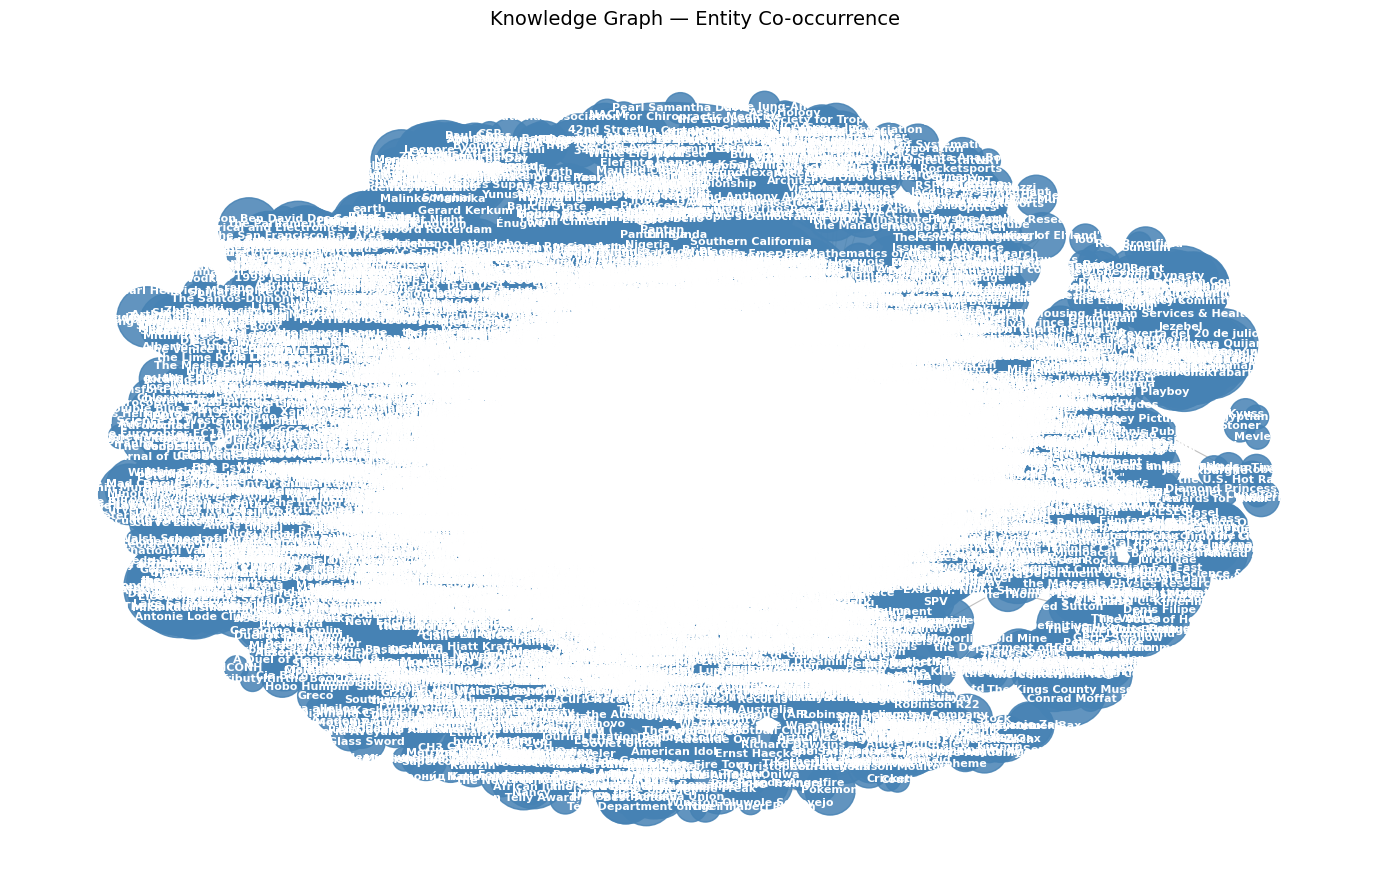

Graph saved to knowledge_graph.png


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 9))
pos    = nx.spring_layout(G, seed=42, k=0.8)
degrees = dict(G.degree())
node_sizes = [300 + degrees[n] * 200 for n in G.nodes()]
edge_weights = [G[u][v]["weight"] for u, v in G.edges()]

nx.draw_networkx_nodes(G, pos, node_size=node_sizes, node_color="steelblue", alpha=0.85)
nx.draw_networkx_labels(G, pos, font_size=8, font_color="white", font_weight="bold")
nx.draw_networkx_edges(G, pos, width=[w * 0.8 for w in edge_weights], alpha=0.5, edge_color="gray")

plt.title("Knowledge Graph — Entity Co-occurrence", fontsize=14)
plt.axis("off")
plt.tight_layout()
plt.savefig("knowledge_graph.png", dpi=150)
plt.show()
print("Graph saved to knowledge_graph.png")

## 💾 Cell 15 — Save Results to JSON

In [ ]:
output = {
    "model": MODEL_ID,
    "k_hop": K_HOP,
    "top_k": TOP_K,
    "metrics": {
        "vanilla_rag": {"exact_match": avg_rag_em, "f1": avg_rag_f1},
        "graphrag":    {"exact_match": avg_graph_em, "f1": avg_graph_f1},
    },
    "per_question": results
}

with open("graphrag_results.json", "w") as f:
    json.dump(output, f, indent=2)

# Download from Colab
from google.colab import files
files.download("graphrag_results.json")
files.download("knowledge_graph.png")
print("✅ Results saved and downloaded")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Results saved and downloaded
